In [13]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# 1. TotalCharges: نص ← رقم (الفراغات = عملاء جدد، نضع 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# 2. توحيد "No internet service" و "No phone service" إلى "No"
cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
        "TechSupport", "StreamingTV", "StreamingMovies"]
df[cols] = df[cols].replace({"No internet service": "No", "No phone service": "No"})

# 3. SeniorCitizen: 0/1 ← No/Yes
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 4. Churn رقمي للتحليل
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

df.to_csv("telco_churn_clean.csv", index=False)
print(df.shape, df.isna().sum().sum())

(7043, 22) 0


In [14]:
# نسبة المغادرة الإجمالية
print("نسبة المغادرة:", round(df["ChurnFlag"].mean() * 100, 1), "%")
print()

# نسبة المغادرة حسب كل عامل
for col in ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen", "TechSupport"]:
    print(col)
    print((df.groupby(col)["ChurnFlag"].mean() * 100).round(1).sort_values(ascending=False))
    print()

# متوسط مدة البقاء والفاتورة الشهرية للمغادرين وغير المغادرين
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))

نسبة المغادرة: 26.5 %

Contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnFlag, dtype: float64

InternetService
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: ChurnFlag, dtype: float64

PaymentMethod
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: ChurnFlag, dtype: float64

SeniorCitizen
SeniorCitizen
Yes    41.7
No     23.6
Name: ChurnFlag, dtype: float64

TechSupport
TechSupport
No     31.2
Yes    15.2
Name: ChurnFlag, dtype: float64

       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4


# Customer Churn Analysis: Telco

## Summary
Of 7,043 customers, **26.5%** churned. This analysis looks at which customer groups leave most often, so the company can focus its retention efforts where they matter most.

## Key Findings

**1. Contract type is the strongest factor.**
Month-to-month customers churn at **42.7%**, compared to 11.3% on one-year contracts and just 2.8% on two-year contracts.

**2. Fiber optic customers churn at more than double the DSL rate.**
41.9% for fiber optic vs 19.0% for DSL and 7.4% for customers with no internet service.

**3. Electronic check users are the most likely to leave.**
45.3% churn, versus 15–19% for every other payment method.

**4. Customers leave early.**
Churned customers stayed 18.0 months on average, against 37.6 months for those who stayed. They also pay more per month (74.4 vs 61.3).

## Recommendations
- Offer discounts or perks to move month-to-month customers onto yearly contracts.
- Review fiber optic pricing and service quality, and follow up with these customers during their first 18 months.
- Encourage electronic check users to switch to automatic payment methods.
- Build an early-warning list: new, month-to-month, fiber, electronic check customers.

## Important Note
These results show **associations, not proven causes**. For example, fiber optic plans cost more, so the higher churn may be driven by price rather than by the technology itself. Confirming causes would need further analysis or a controlled test.

## Data Preparation
- Converted `TotalCharges` to numeric (11 blank values belonged to brand-new customers and were set to 0).
- Unified "No internet service" and "No phone service" into "No".
- Converted `SeniorCitizen` from 0/1 to No/Yes.
- Added a numeric `ChurnFlag` column.
- Final dataset: 7,043 rows, 22 columns, no missing values.

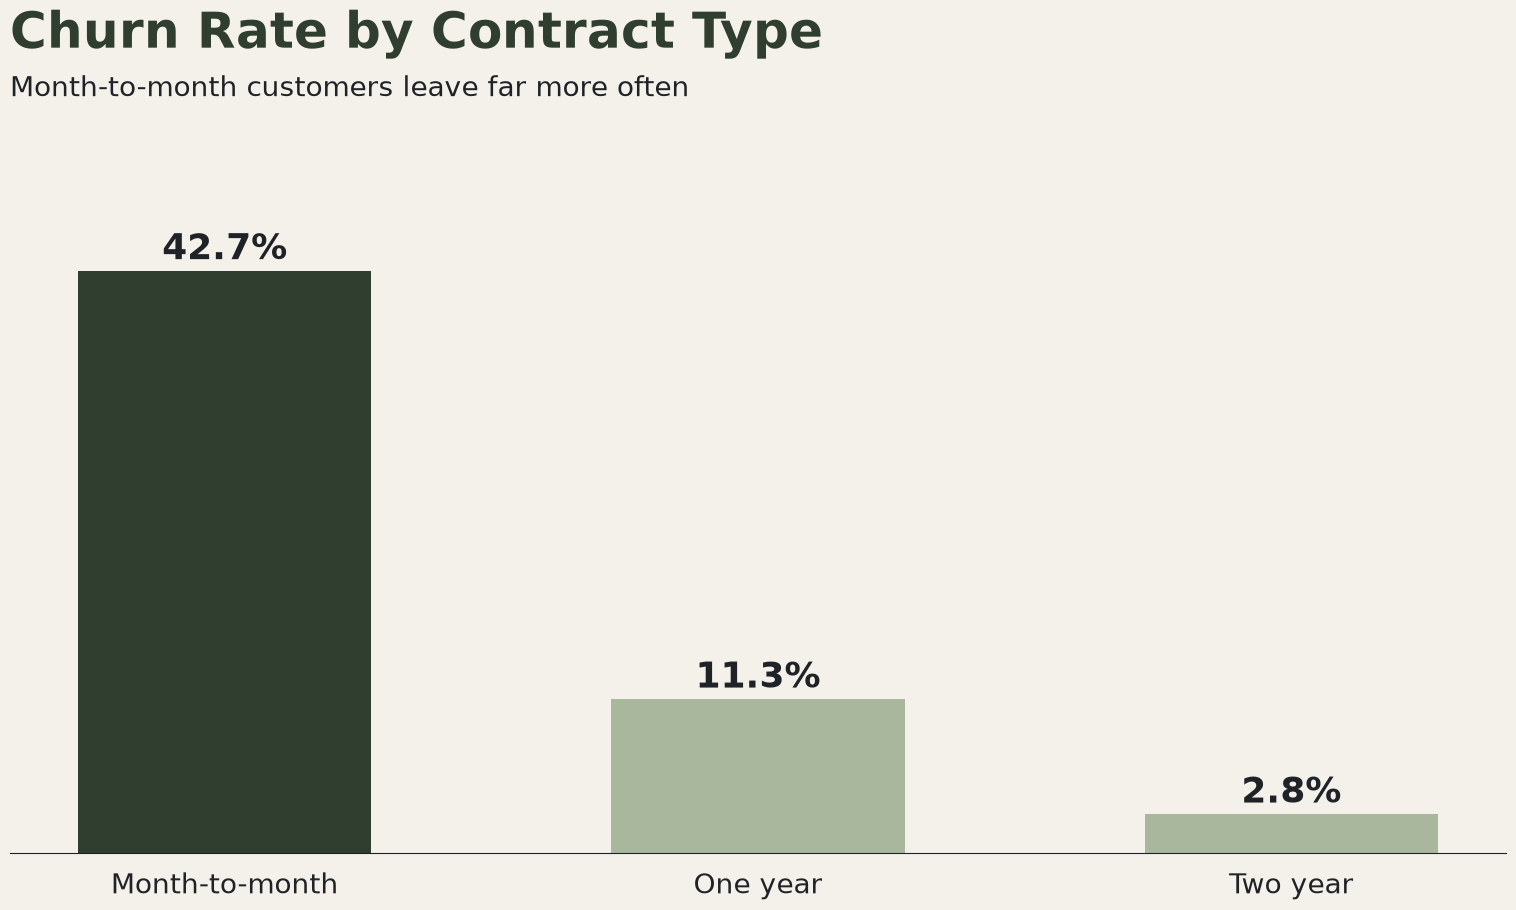

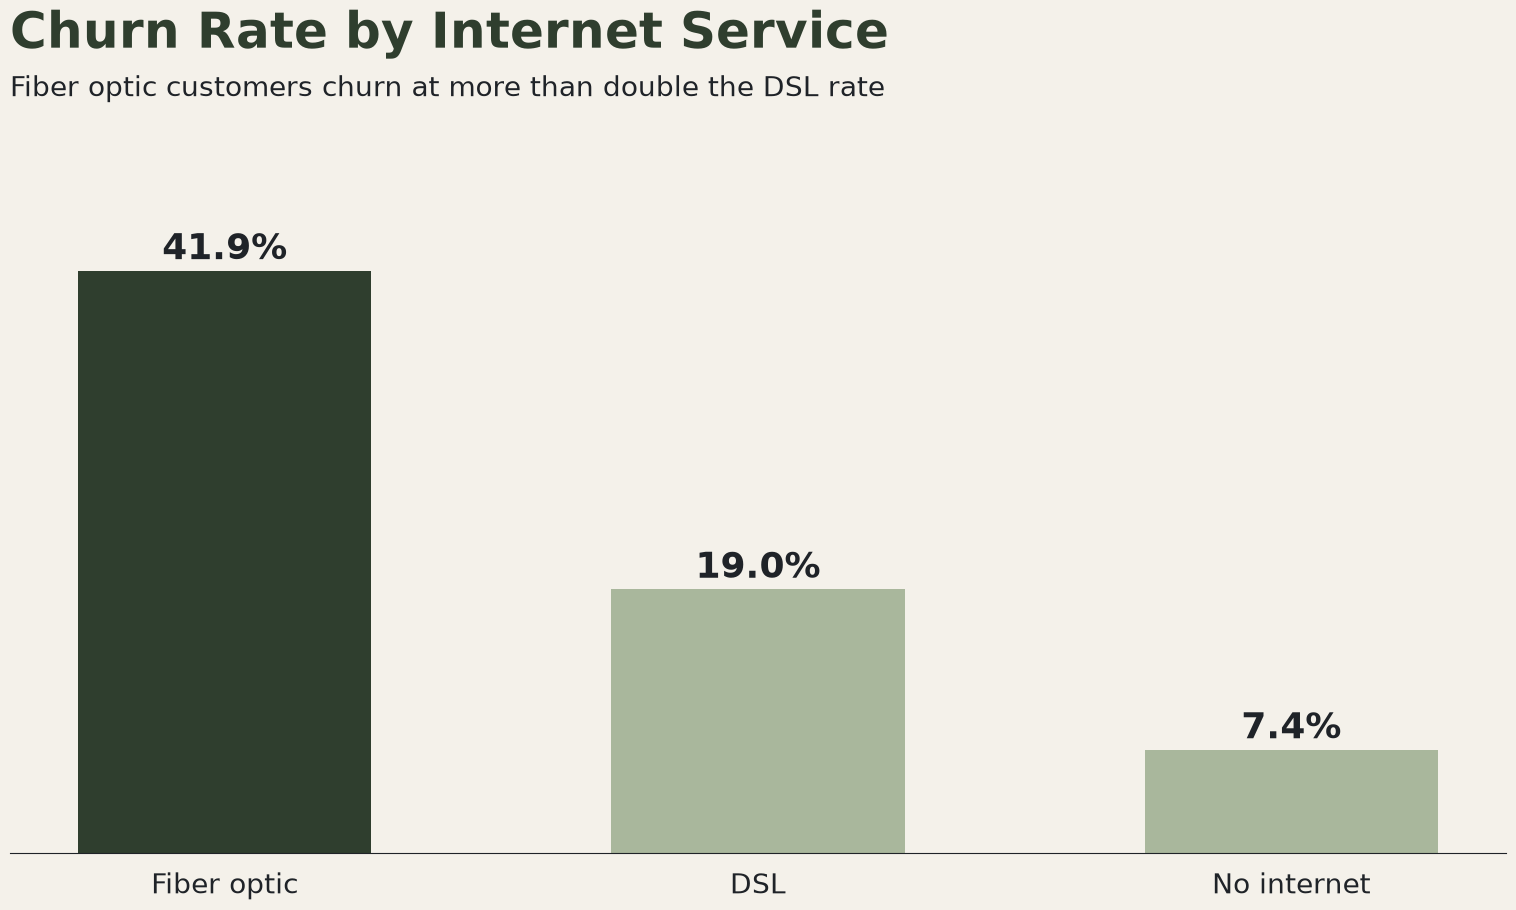

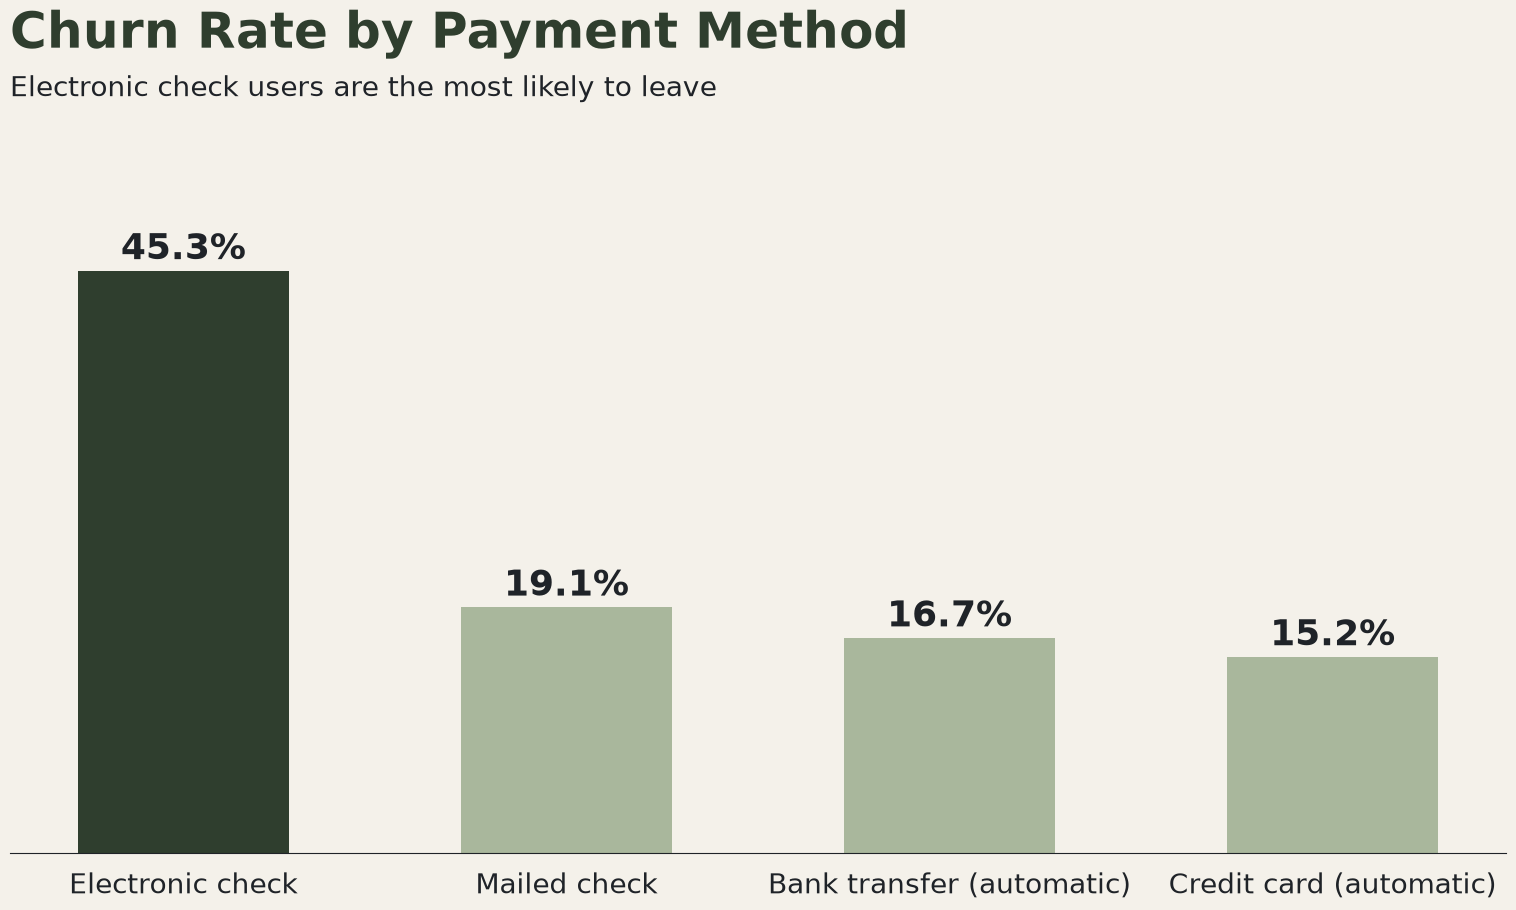

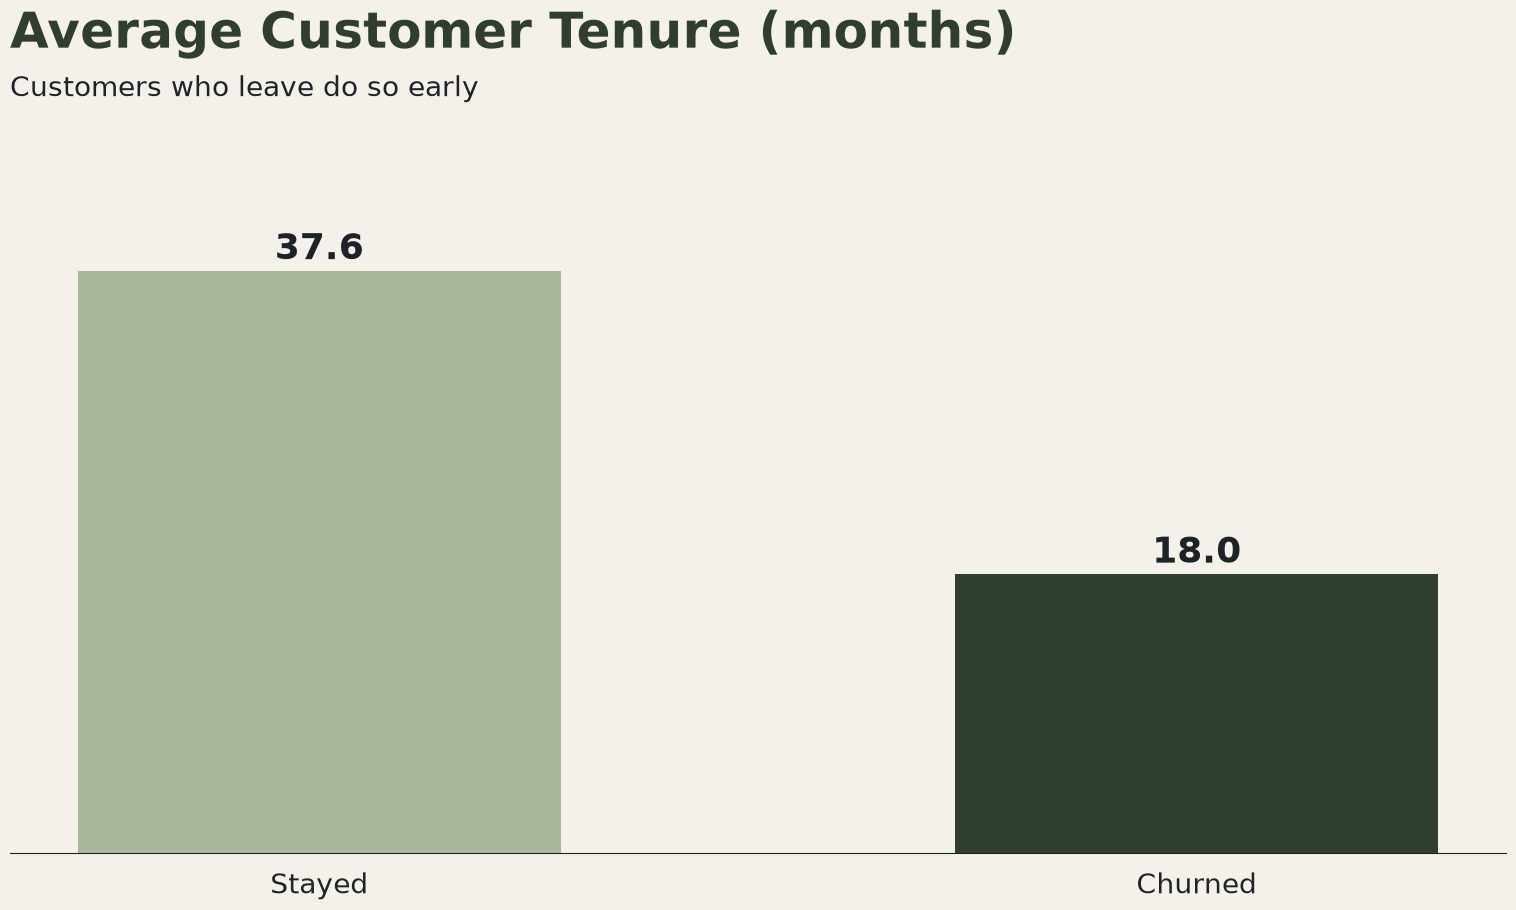

In [15]:
import matplotlib.pyplot as plt
import os

OLIVE, SAGE, BG, TEXT = "#2F3E2E", "#A9B79C", "#F4F1EA", "#1F2328"
os.makedirs("charts", exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT, "font.size": 20,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.edgecolor": TEXT,
})

def bar_chart(series, title, subtitle, filename, unit="%", sort=True, highlight=None):
    if sort:
        series = series.sort_values(ascending=False)
    top = highlight if highlight else series.idxmax()
    colors = [OLIVE if k == top else SAGE for k in series.index]

    fig, ax = plt.subplots(figsize=(17, 9.7), dpi=100)
    bars = ax.bar(series.index, series.values, color=colors, width=0.55)
    for b, v in zip(bars, series.values):
        ax.text(b.get_x() + b.get_width() / 2, v + series.max() * 0.02,
                f"{v:.1f}{unit}", ha="center", fontsize=26, fontweight="bold")
    ax.set_yticks([])
    ax.tick_params(axis="x", length=0, pad=14)
    ax.set_ylim(0, series.max() * 1.2)
    fig.text(0.06, 0.93, title, fontsize=36, fontweight="bold", color=OLIVE)
    fig.text(0.06, 0.88, subtitle, fontsize=20)
    plt.subplots_adjust(top=0.82, left=0.06, right=0.94, bottom=0.1)
    fig.savefig(f"charts/{filename}.png")
    plt.show()

rate = lambda col: df.groupby(col)["ChurnFlag"].mean() * 100

bar_chart(rate("Contract"), "Churn Rate by Contract Type",
          "Month-to-month customers leave far more often", "1_contract")

bar_chart(rate("InternetService").rename({"No": "No internet"}),
          "Churn Rate by Internet Service",
          "Fiber optic customers churn at more than double the DSL rate", "2_internet")

bar_chart(rate("PaymentMethod"), "Churn Rate by Payment Method",
          "Electronic check users are the most likely to leave", "3_payment")

tenure = df.groupby("Churn")["tenure"].mean().rename({"No": "Stayed", "Yes": "Churned"})
bar_chart(tenure, "Average Customer Tenure (months)",
          "Customers who leave do so early", "4_tenure",
          unit="", sort=False, highlight="Churned")